In [213]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt 
import warnings
warnings.filterwarnings('ignore')

In [214]:
df=pd.read_csv("heart.csv")
df


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0
...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,M,TA,110,264,0,Normal,132,N,1.2,Flat,1
914,68,M,ASY,144,193,1,Normal,141,N,3.4,Flat,1
915,57,M,ASY,130,131,0,Normal,115,Y,1.2,Flat,1
916,57,F,ATA,130,236,0,LVH,174,N,0.0,Flat,1


In [215]:
# EDA

In [216]:
df.shape



(918, 12)

In [217]:
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [218]:
df.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [219]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [220]:
df.isnull().sum()

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

In [221]:
df.columns



Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope',
       'HeartDisease'],
      dtype='object')

<Axes: xlabel='HeartDisease'>

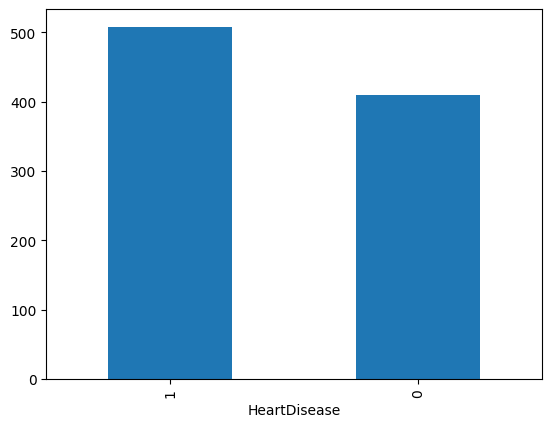

In [222]:
df['HeartDisease'].value_counts().plot(kind='bar')

In [223]:
df.duplicated().sum()

np.int64(0)

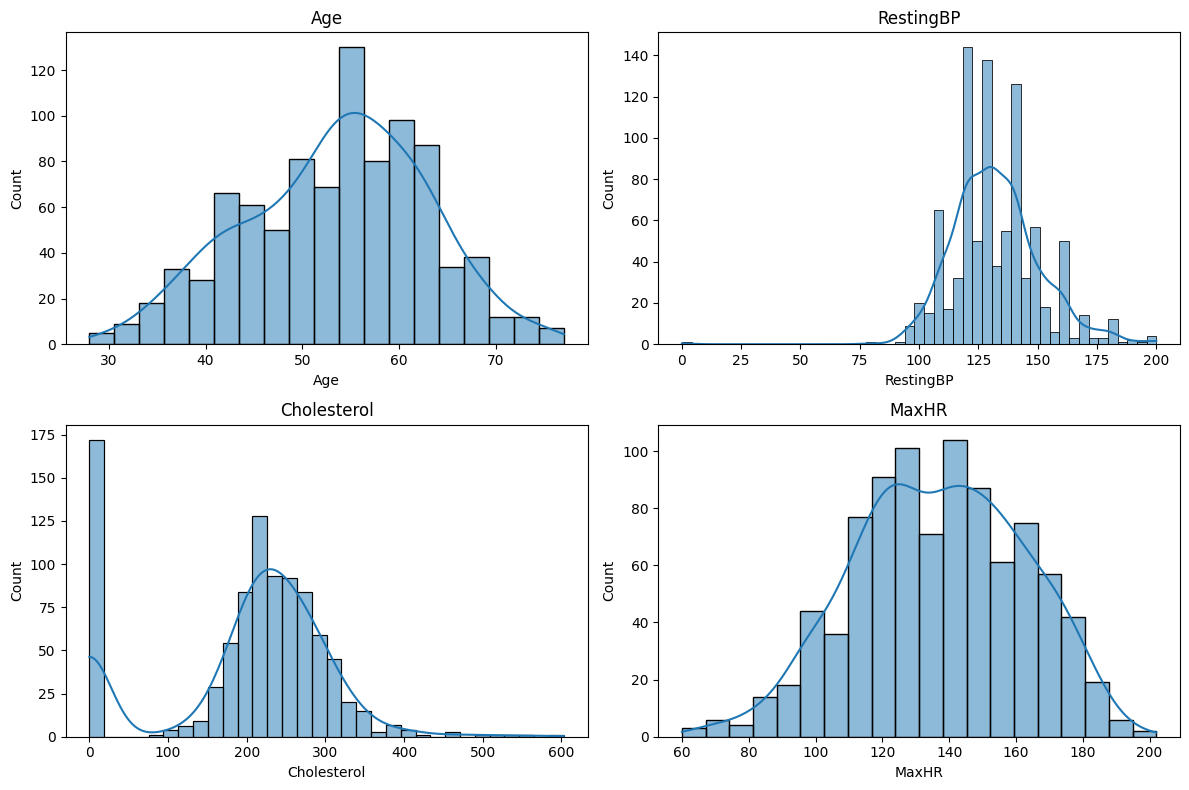

In [224]:
import matplotlib.pyplot as plt
import seaborn as sns

def plotting(var, num):
    plt.subplot(2, 2, num)
    sns.histplot(df[var], kde=True)
    plt.title(var)

plt.figure(figsize=(12, 8))

plotting('Age', 1)
plotting('RestingBP', 2)
plotting('Cholesterol', 3)
plotting('MaxHR', 4)
plt.tight_layout()


In [225]:
df['Cholesterol'].value_counts()

Cholesterol
0      172
254     11
223     10
220     10
230      9
      ... 
392      1
316      1
153      1
466      1
131      1
Name: count, Length: 222, dtype: int64

In [226]:
# person cannot have 0 cholestron so data is still not correct so fill them with mean


In [227]:
ch_mean=df.loc[df['Cholesterol']!=0,'Cholesterol'].mean()

In [228]:
ch_mean

np.float64(244.6353887399464)

In [229]:
df['Cholesterol']=df['Cholesterol'].replace(0,ch_mean)

In [230]:
df

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289.0,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180.0,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283.0,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214.0,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195.0,0,Normal,122,N,0.0,Up,0
...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,M,TA,110,264.0,0,Normal,132,N,1.2,Flat,1
914,68,M,ASY,144,193.0,1,Normal,141,N,3.4,Flat,1
915,57,M,ASY,130,131.0,0,Normal,115,Y,1.2,Flat,1
916,57,F,ATA,130,236.0,0,LVH,174,N,0.0,Flat,1


In [231]:
df['Cholesterol'].value_counts()

Cholesterol
244.635389    172
254.000000     11
223.000000     10
220.000000     10
230.000000      9
             ... 
392.000000      1
316.000000      1
153.000000      1
466.000000      1
131.000000      1
Name: count, Length: 222, dtype: int64

In [232]:
df['Cholesterol']=df['Cholesterol'].round(2)


In [233]:
df['Cholesterol'].value_counts()

Cholesterol
244.64    172
254.00     11
223.00     10
220.00     10
230.00      9
         ... 
392.00      1
316.00      1
153.00      1
466.00      1
131.00      1
Name: count, Length: 222, dtype: int64

In [234]:
restingbp_mean=df.loc[df['RestingBP']!=0,'RestingBP'].mean()
restingbp_mean

np.float64(132.54089422028352)

In [235]:
df['RestingBP']=df['RestingBP'].replace(0,restingbp_mean)

In [236]:
df['RestingBP'].value_counts()

RestingBP
120.0    132
130.0    118
140.0    107
110.0     58
150.0     55
        ... 
185.0      1
98.0       1
92.0       1
113.0      1
164.0      1
Name: count, Length: 67, dtype: int64

In [237]:
df['RestingBP']=df['RestingBP'].round(2)

In [238]:
df['RestingBP'].value_counts()

RestingBP
120.0    132
130.0    118
140.0    107
110.0     58
150.0     55
        ... 
185.0      1
98.0       1
92.0       1
113.0      1
164.0      1
Name: count, Length: 67, dtype: int64

In [239]:
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140.0,289.0,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160.0,180.0,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130.0,283.0,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138.0,214.0,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150.0,195.0,0,Normal,122,N,0.0,Up,0


<Axes: xlabel='FastingBS'>

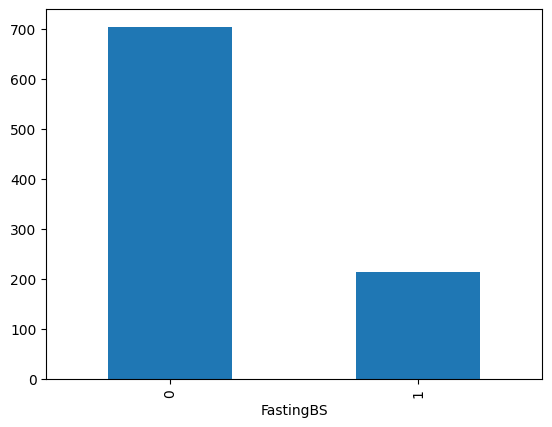

In [240]:
df['FastingBS'].value_counts().plot(kind='bar')

In [241]:
df['Sex']=df['Sex'].map({'M':0,'F':1})


In [242]:
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,0,ATA,140.0,289.0,0,Normal,172,N,0.0,Up,0
1,49,1,NAP,160.0,180.0,0,Normal,156,N,1.0,Flat,1
2,37,0,ATA,130.0,283.0,0,ST,98,N,0.0,Up,0
3,48,1,ASY,138.0,214.0,0,Normal,108,Y,1.5,Flat,1
4,54,0,NAP,150.0,195.0,0,Normal,122,N,0.0,Up,0


<Axes: xlabel='HeartDisease', ylabel='Cholesterol'>

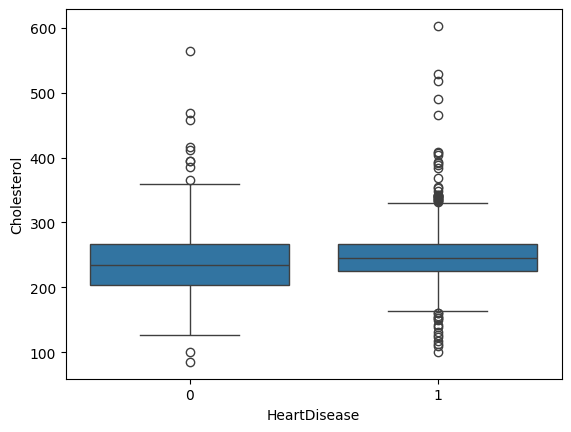

In [243]:
sns.boxplot(x='HeartDisease',y='Cholesterol',data=df)

<Axes: xlabel='HeartDisease', ylabel='RestingBP'>

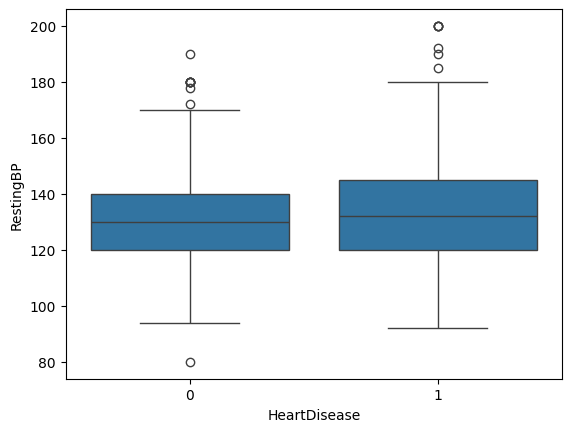

In [244]:
sns.boxplot(x="HeartDisease",y="RestingBP",data=df)

<Axes: >

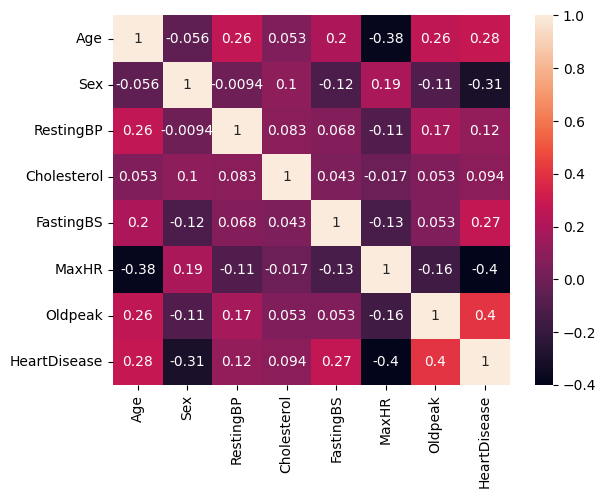

In [245]:
# plt.figure(figsize=(14, 10))
sns.heatmap(df.corr(numeric_only=True),annot=True)

# Data preprocessing

In [246]:
df_encoded=pd.get_dummies(df,drop_first=True)

In [247]:
df_encoded

,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,40,0,140.0,289.0,0,172,0.0,0,True,False,False,True,False,False,False,True
1,49,1,160.0,180.0,0,156,1.0,1,False,True,False,True,False,False,True,False
2,37,0,130.0,283.0,0,98,0.0,0,True,False,False,False,True,False,False,True
3,48,1,138.0,214.0,0,108,1.5,1,False,False,False,True,False,True,True,False
4,54,0,150.0,195.0,0,122,0.0,0,False,True,False,True,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,0,110.0,264.0,0,132,1.2,1,False,False,True,True,False,False,True,False
914,68,0,144.0,193.0,1,141,3.4,1,False,False,False,True,False,False,True,False
915,57,0,130.0,131.0,0,115,1.2,1,False,False,False,True,False,True,True,False
916,57,1,130.0,236.0,0,174,0.0,1,True,False,False,False,False,False,True,False


In [248]:
df_encoded=df_encoded.astype(int)

In [249]:
df_encoded

,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,40,0,140,289,0,172,0,0,1,0,0,1,0,0,0,1
1,49,1,160,180,0,156,1,1,0,1,0,1,0,0,1,0
2,37,0,130,283,0,98,0,0,1,0,0,0,1,0,0,1
3,48,1,138,214,0,108,1,1,0,0,0,1,0,1,1,0
4,54,0,150,195,0,122,0,0,0,1,0,1,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,0,110,264,0,132,1,1,0,0,1,1,0,0,1,0
914,68,0,144,193,1,141,3,1,0,0,0,1,0,0,1,0
915,57,0,130,131,0,115,1,1,0,0,0,1,0,1,1,0
916,57,1,130,236,0,174,0,1,1,0,0,0,0,0,1,0


In [250]:
from sklearn.preprocessing import StandardScaler
numerical_cols=['Age','RestingBP','Cholesterol','MaxHR','Oldpeak']
scaler=StandardScaler()
df_encoded[numerical_cols]=scaler.fit_transform(df_encoded[numerical_cols])
df_encoded.head()

,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,-1.433140,0,0.414885,0.834754,0,1.382928,-0.727592,0,1,0,0,1,0,0,0,1
1,-0.478484,1,1.527224,-1.210675,0,0.754157,0.282891,1,0,1,0,1,0,0,1,0
2,-1.751359,0,-0.141284,0.722161,0,-1.525138,-0.727592,0,1,0,0,0,1,0,0,1
3,-0.584556,1,0.303651,-0.572651,0,-1.132156,0.282891,1,0,0,0,1,0,1,1,0
4,0.051881,0,0.971054,-0.929194,0,-0.581981,-0.727592,0,0,1,0,1,0,0,0,1


In [251]:
df_encoded

,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,-1.433140,0,0.414885,0.834754,0,1.382928,-0.727592,0,1,0,0,1,0,0,0,1
1,-0.478484,1,1.527224,-1.210675,0,0.754157,0.282891,1,0,1,0,1,0,0,1,0
2,-1.751359,0,-0.141284,0.722161,0,-1.525138,-0.727592,0,1,0,0,0,1,0,0,1
3,-0.584556,1,0.303651,-0.572651,0,-1.132156,0.282891,1,0,0,0,1,0,1,1,0
4,0.051881,0,0.971054,-0.929194,0,-0.581981,-0.727592,0,0,1,0,1,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
913,-0.902775,0,-1.253622,0.365619,0,-0.188999,0.282891,1,0,0,1,1,0,0,1,0
914,1.536902,0,0.637353,-0.966725,1,0.164684,2.303858,1,0,0,0,1,0,0,1,0
915,0.370100,0,-0.141284,-2.130180,0,-0.857069,0.282891,1,0,0,0,1,0,1,1,0
916,0.370100,1,-0.141284,-0.159813,0,1.461525,-0.727592,1,1,0,0,0,0,0,1,0


In [252]:
df_encoded.columns

Index(['Age', 'Sex', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR',
       'Oldpeak', 'HeartDisease', 'ChestPainType_ATA', 'ChestPainType_NAP',
       'ChestPainType_TA', 'RestingECG_Normal', 'RestingECG_ST',
       'ExerciseAngina_Y', 'ST_Slope_Flat', 'ST_Slope_Up'],
      dtype='object')

In [253]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier


In [254]:
X=df_encoded.drop("HeartDisease",axis=1)
y=df_encoded['HeartDisease']

In [255]:
    X

,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,-1.433140,0,0.414885,0.834754,0,1.382928,-0.727592,1,0,0,1,0,0,0,1
1,-0.478484,1,1.527224,-1.210675,0,0.754157,0.282891,0,1,0,1,0,0,1,0
2,-1.751359,0,-0.141284,0.722161,0,-1.525138,-0.727592,1,0,0,0,1,0,0,1
3,-0.584556,1,0.303651,-0.572651,0,-1.132156,0.282891,0,0,0,1,0,1,1,0
4,0.051881,0,0.971054,-0.929194,0,-0.581981,-0.727592,0,1,0,1,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
913,-0.902775,0,-1.253622,0.365619,0,-0.188999,0.282891,0,0,1,1,0,0,1,0
914,1.536902,0,0.637353,-0.966725,1,0.164684,2.303858,0,0,0,1,0,0,1,0
915,0.370100,0,-0.141284,-2.130180,0,-0.857069,0.282891,0,0,0,1,0,1,1,0
916,0.370100,1,-0.141284,-0.159813,0,1.461525,-0.727592,1,0,0,0,0,0,1,0


In [256]:
y

0      0
1      1
2      0
3      1
4      0
      ..
913    1
914    1
915    1
916    1
917    0
Name: HeartDisease, Length: 918, dtype: int64

In [257]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)


In [258]:
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.fit_transform(X_test)

In [263]:
models={
    "Logistic Regression":LogisticRegression(),
    "KNN": KNeighborsClassifier(),
    "Naive Bayes":GaussianNB(),
    "Decision Tree":DecisionTreeClassifier(),
    "SVM":SVC(probability=True)
}


In [264]:
result=[]

In [265]:
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    result.append({
        'model': name,
        'Accuracy': round(acc, 4),
        'F1_score': round(f1, 4)
    })

In [266]:
result

[{'model': 'Logistic Regression', 'Accuracy': 0.8696, 'F1_score': 0.8857},
 {'model': 'KNN', 'Accuracy': 0.8641, 'F1_score': 0.8815},
 {'model': 'Naive Bayes', 'Accuracy': 0.8533, 'F1_score': 0.8683},
 {'model': 'Decision Tree', 'Accuracy': 0.7663, 'F1_score': 0.7902},
 {'model': 'SVM', 'Accuracy': 0.8478, 'F1_score': 0.8679}]

In [268]:
# logistic regression is performing well
# save them

In [270]:
import joblib
joblib.dump(models["Logistic Regression"],'LR_heart.pkl')
joblib.dump(scaler,'scaler.pkl')
joblib.dump(X.columns.tolist(),'columns.pkl')

['columns.pkl']

In [282]:
import joblib

model = joblib.load('LR_heart.pkl')
print(model)

LogisticRegression()


In [283]:
import os

print(os.path.abspath('LR_heart.pkl'))
print(os.path.exists('LR_heart.pkl'))

/Users/priya/Practical_ml/LR_heart.pkl
True


In [284]:
import joblib

path = '/Users/priya/Practical_ml/LR_heart.pkl'

model = joblib.load(path)

print(type(model))
print(model)

<class 'sklearn.linear_model._logistic.LogisticRegression'>
LogisticRegression()
